# TP1 — Contagem e Classificação de Peças de Lego Retangulares

Pipeline de segmentação e extração de propriedades, desenvolvido a partir da imagem `lego01.jpg` e validado nas 14 imagens de treino.

In [270]:
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt

## 1. Leitura da imagem e espaços de cor
Lê-se a imagem de exemplo e convertem-se para cinzentos, RGB e HSV.

In [271]:
caminho_exemplo = os.path.join("./treino", "lego01.jpg")

img = cv2.imread(caminho_exemplo)
img_gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
img_hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)

h, s, v = cv2.split(img_hsv)

## 2. Histogramas de H e S

A mesa ocupa a maior parte da imagem, por isso o pico de cada histograma corresponde à cor da mesa.

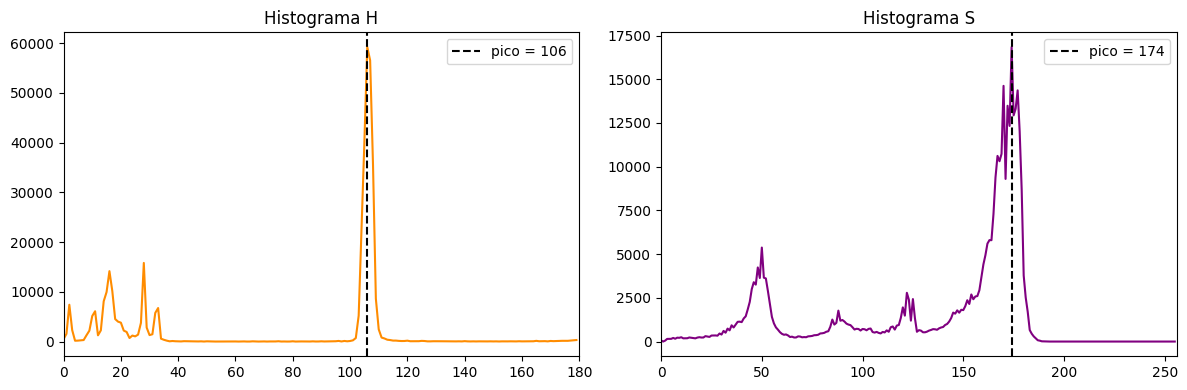

Pico H: 106 | Pico S: 174


In [272]:
histH = cv2.calcHist([h], [0], None, [180], [0, 180])
histS = cv2.calcHist([s], [0], None, [256], [0, 256])

maxH = np.argmax(histH)
maxS = np.argmax(histS)

fig, axs = plt.subplots(1, 2, figsize=(12, 4))

axs[0].plot(histH, color="darkorange")
axs[0].axvline(maxH, color="black", linestyle="--", label=f"pico = {maxH}")
axs[0].set_title("Histograma H")
axs[0].set_xlim([0, 180])
axs[0].legend()

axs[1].plot(histS, color="purple")
axs[1].axvline(maxS, color="black", linestyle="--", label=f"pico = {maxS}")
axs[1].set_title("Histograma S")
axs[1].set_xlim([0, 256])
axs[1].legend()

plt.tight_layout()
plt.show()

print("Pico H:", maxH, "| Pico S:", maxS)

## 3. Segmentação por cor da mesa (HSV + inRange)

Define-se um intervalo [pico - margem, pico + margem] em H e S à volta da cor da mesa. A máscara da mesa é invertida para ter a máscara das peças, e limpa-se com morfologia (open + close).

In [273]:
margem_h = 60
margem_s = 60

h_min, h_max = np.clip(maxH - margem_h, 0, 179), np.clip(maxH + margem_h, 0, 179)
s_min, s_max = np.clip(maxS - margem_s, 0, 255), np.clip(maxS + margem_s, 0, 255)

minimo = np.array([h_min, s_min, 0], dtype=np.uint8)
maximo = np.array([h_max, s_max, 255], dtype=np.uint8)

mascara_mesa = cv2.inRange(img_hsv, minimo, maximo)
mascara_peca = cv2.bitwise_not(mascara_mesa)

closed = cv2.morphologyEx(mascara_peca, cv2.MORPH_CLOSE, kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (5, 5)))
eroded = cv2.erode(closed, cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (15, 15)), iterations=4)
dilated = cv2.dilate(eroded, cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (15,15)), iterations=3)


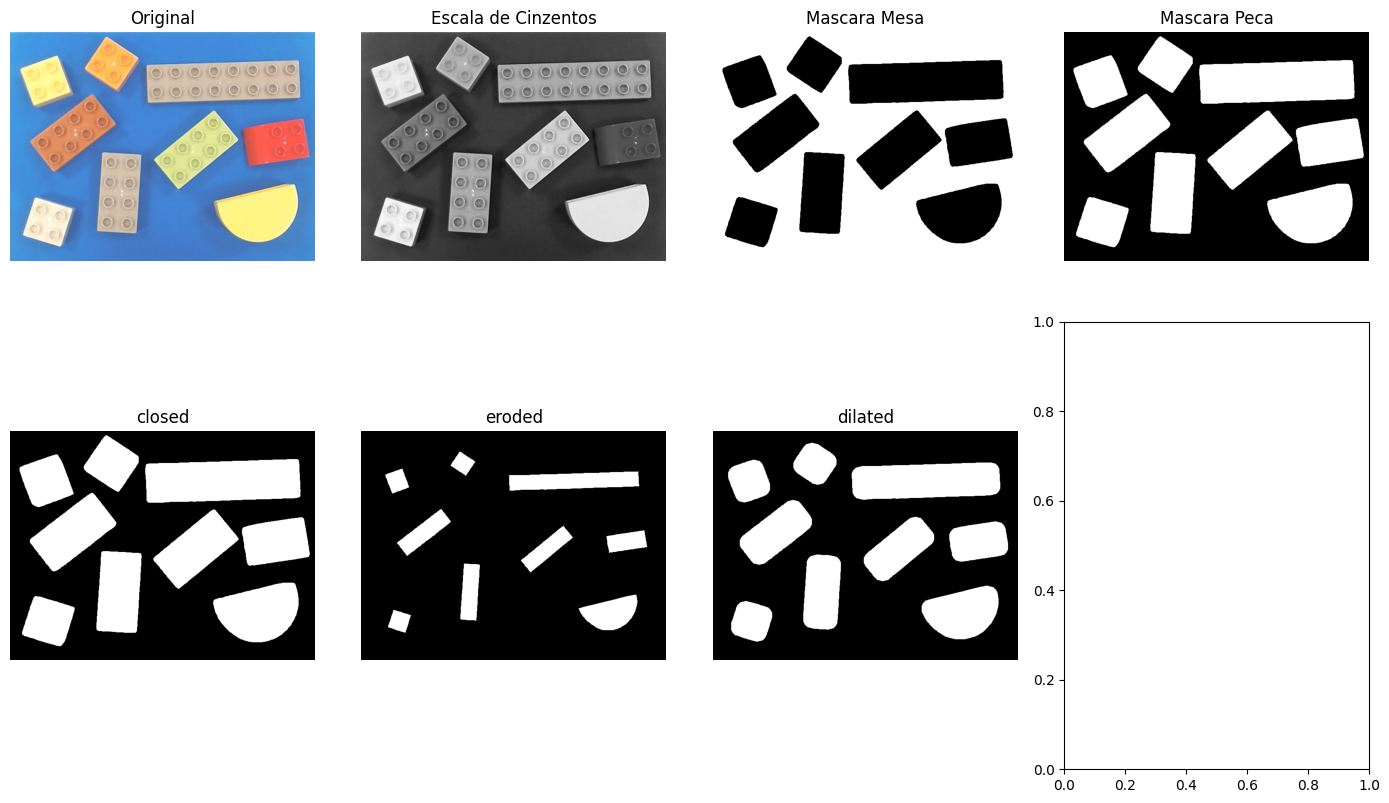

In [274]:
imagens = [img_rgb, img_gray, mascara_mesa, mascara_peca, closed, eroded, dilated]
titulos = ["Original", "Escala de Cinzentos", "Mascara Mesa", "Mascara Peca", "closed", "eroded", "dilated"]

fig, axs = plt.subplots(2, 4, figsize=(14, 9))
for ax, imagem, titulo in zip(axs.flat, imagens, titulos):
    ax.imshow(imagem, cmap="gray")
    ax.set_title(titulo)
    ax.axis("off")
plt.tight_layout()
plt.show()

## Função final para todas as imagens

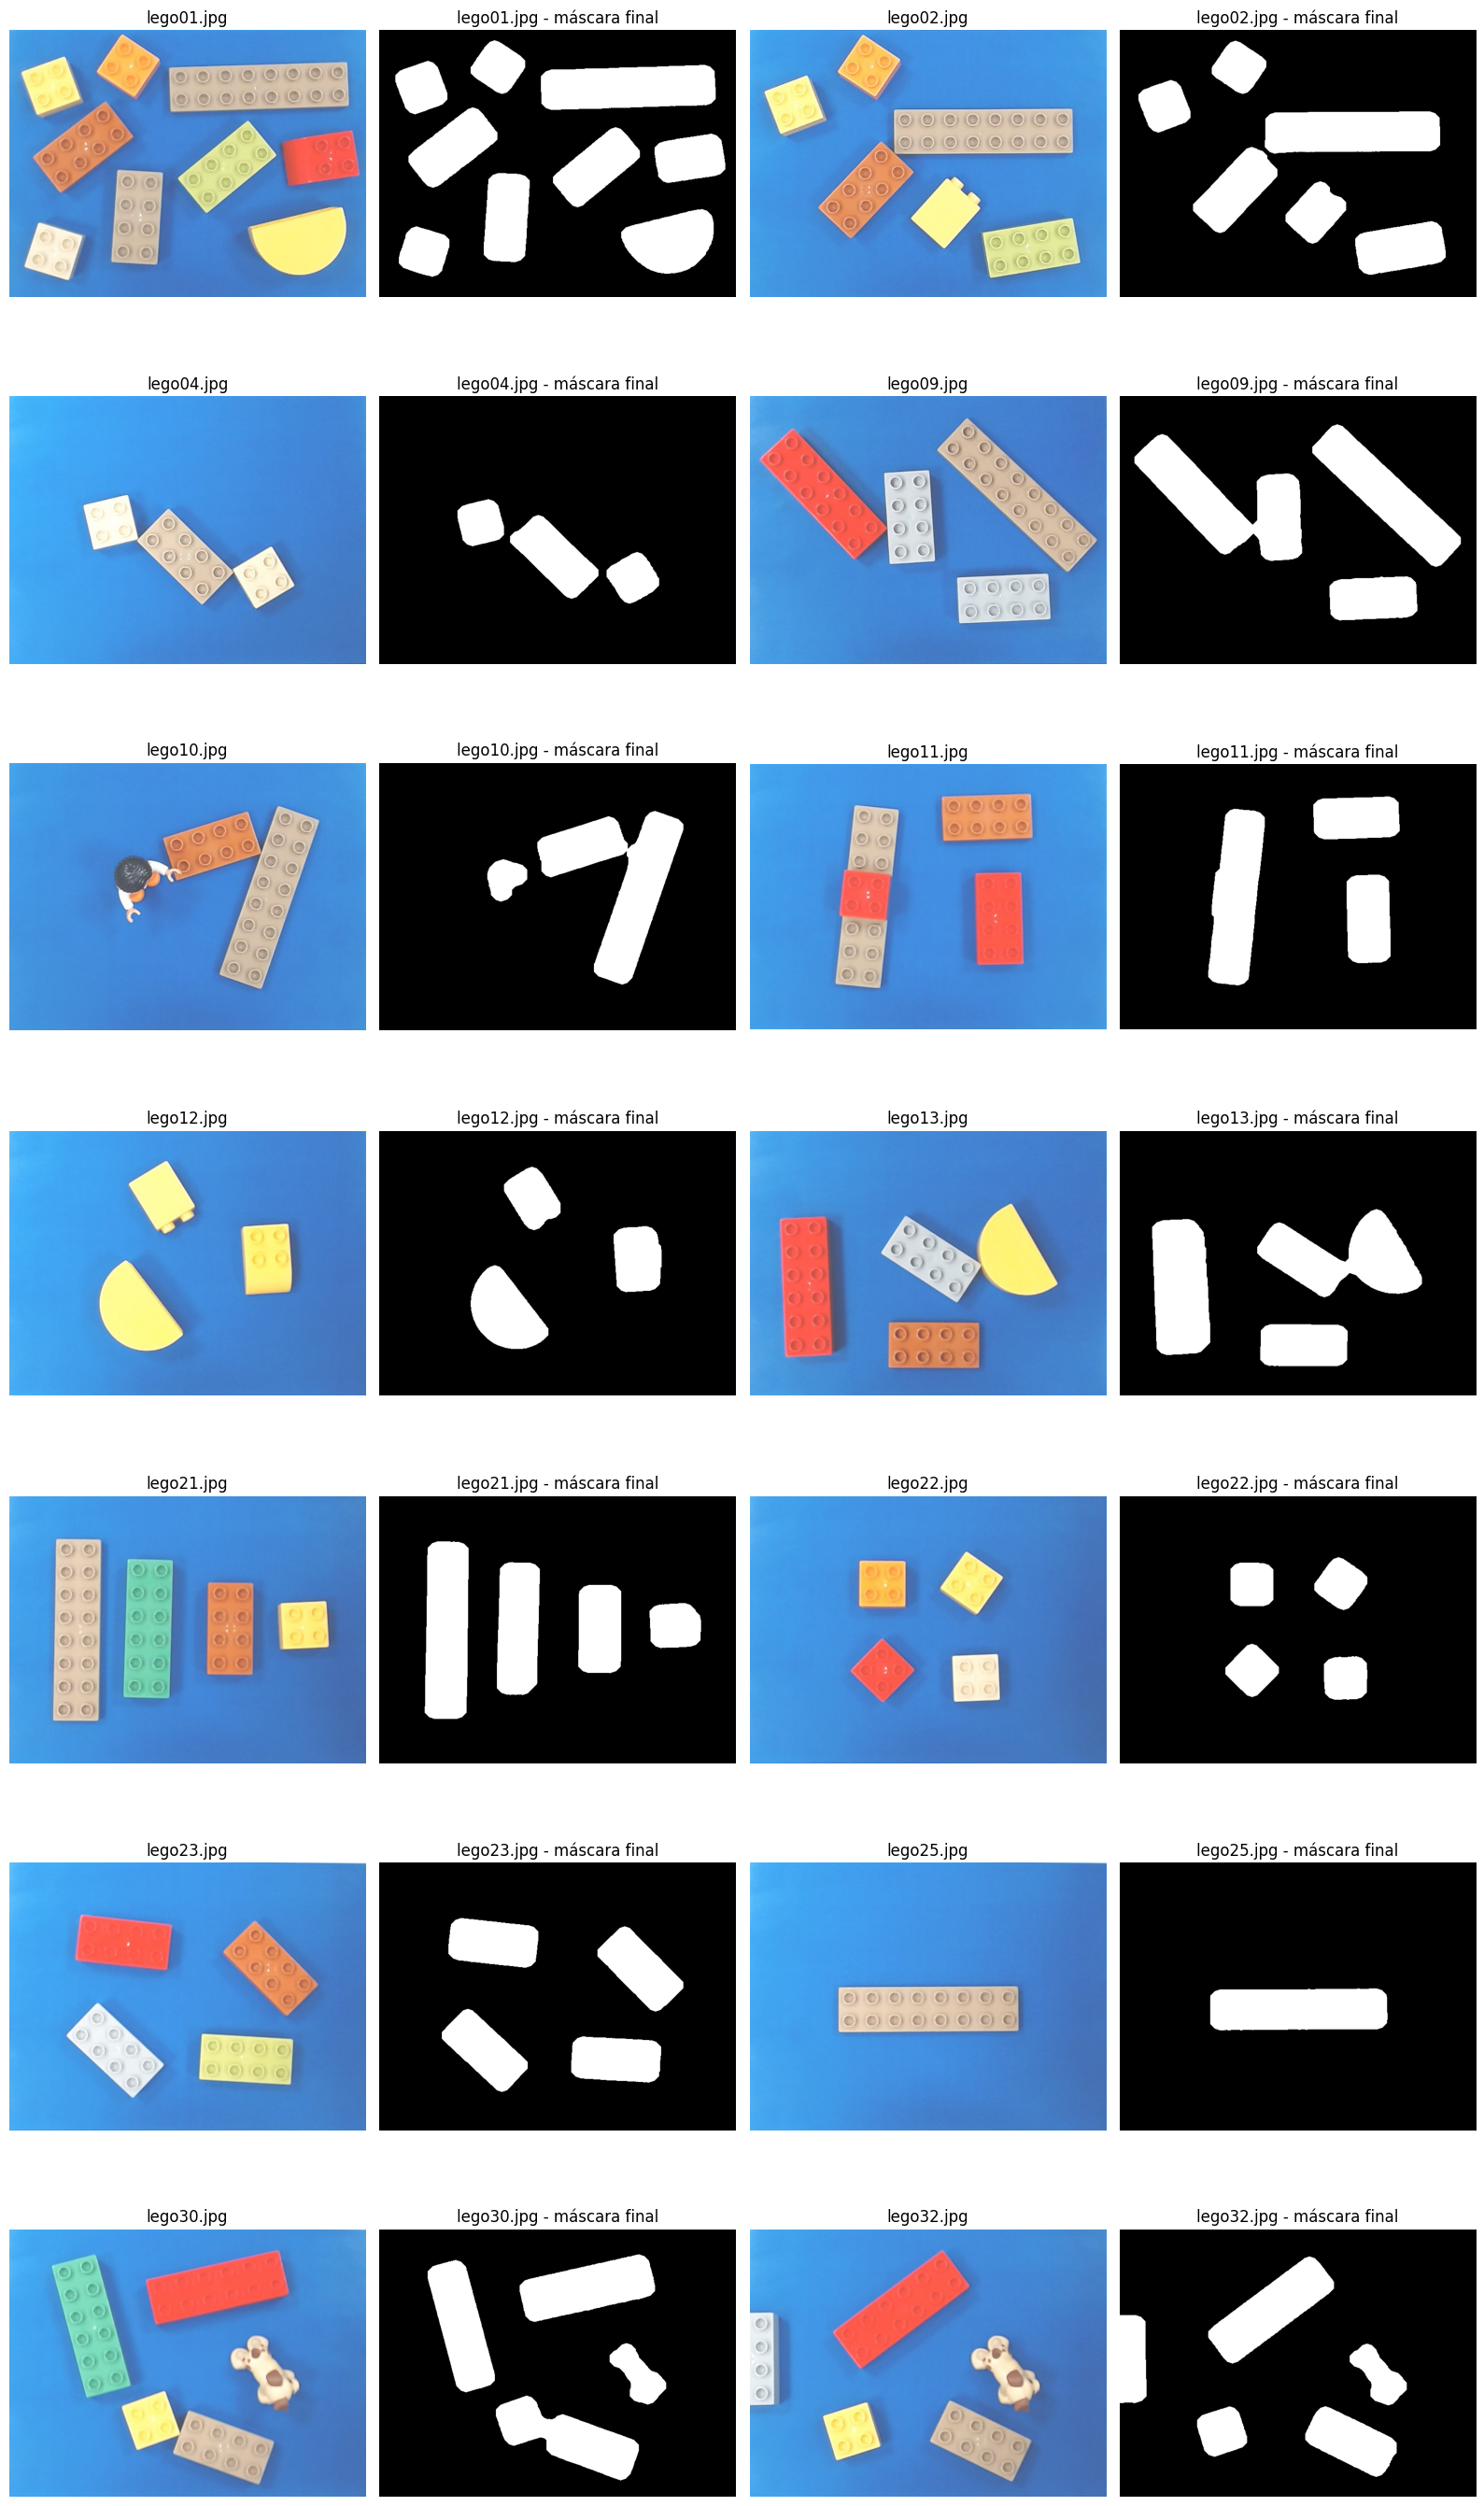

In [ ]:
def ProcessarImagem(img_bgr, margem_h=50, margem_s=50, tam_kernel=15, it_erode=4, it_dilate=3):
    img_hsv = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2HSV)
    h, s, v = cv2.split(img_hsv)

    # cor da mesa = pico dos histogramas de H e S (calculado para cada imagem)
    histH = cv2.calcHist([h], [0], None, [180], [0, 180])
    histS = cv2.calcHist([s], [0], None, [256], [0, 256])
    maxH = np.argmax(histH)
    maxS = np.argmax(histS)

    h_min, h_max = np.clip(maxH - margem_h, 0, 179), np.clip(maxH + margem_h, 0, 179)
    s_min, s_max = np.clip(maxS - margem_s, 0, 255), np.clip(maxS + margem_s, 0, 255)

    minimo = np.array([h_min, s_min, 0], dtype=np.uint8)
    maximo = np.array([h_max, s_max, 255], dtype=np.uint8)

    mascara_mesa = cv2.inRange(img_hsv, minimo, maximo)
    mascara_peca = cv2.bitwise_not(mascara_mesa)

    kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (tam_kernel, tam_kernel))
    closed = cv2.morphologyEx(mascara_peca, cv2.MORPH_CLOSE, kernel=cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (5, 5)))
    eroded = cv2.erode(closed, kernel, iterations=it_erode)
    dilated = cv2.dilate(eroded, kernel, iterations=it_dilate)

    return dilated


imagens_dir = './treino/'

# lista com os nomes dos ficheiros, ordenada (lego01, lego02, ...)
nomes = sorted(f for f in os.listdir(imagens_dir) if f.endswith('.jpg'))

# 2 pares (original + máscara) por linha
n_linhas = (len(nomes) + 1) // 2
fig, axs = plt.subplots(n_linhas, 4, figsize=(16, 4 * n_linhas))

for ax in axs.flat:
    ax.axis('off')

for i, nome in enumerate(nomes):
    img_bgr = cv2.imread(os.path.join(imagens_dir, nome))
    resultado = ProcessarImagem(img_bgr)

    ax_orig, ax_res = axs.flat[2 * i], axs.flat[2 * i + 1]
    ax_orig.imshow(cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB))
    ax_orig.set_title(nome)
    ax_res.imshow(resultado, cmap='gray')
    ax_res.set_title(f'{nome} - máscara final')

plt.tight_layout()
plt.show()
